# Adaptive conformal inference via replay

[ACI](../conformal-prediction.md#adaptive-conformal-inference-via-replay) adapts the miscoverage probability
using chronologically revealed absolute forecast errors. Its state is reconstructed inside each forecast
call, following the same stateless interface as PID. This is **not a persistent online session**, and it
does not inherit the original algorithm's long-run coverage guarantee across calls.

We first plot a usable finite forecast, then evaluate held-out coverage together with interval width and
non-finite sets. The real-data example uses Chronos-Bolt tiny on M4 Hourly; GPU is optional.


In [ ]:
!UV_CONSTRAINT= UV_BUILD_CONSTRAINT= uv pip install -q "foundationforecast[plot]"


In [1]:
import numpy as np
import pandas as pd

from foundationforecast import ACI, PID, ConformalIntervals, FoundationForecast
from foundationforecast.models import Chronos

df = pd.read_parquet("https://timecopilot.s3.amazonaws.com/public/data/m4-hourly.parquet")
df = df[df["unique_id"].isin(df["unique_id"].unique()[:4])].copy()
h = 24
level = [80, 95]
n_windows = 20


## A finite forecast before evaluation

Use one series, 20 calibration windows and `gamma=0.005`. The first 10 windows seed the error distribution;
the remaining 10 update alpha. Each forecast costs about 21 panel point forecasts and needs at least
481 historical observations (`h=step_size=24`). These settings are illustrative, not a general calibration
recommendation. Both returned levels are checked for finite bounds before plotting.


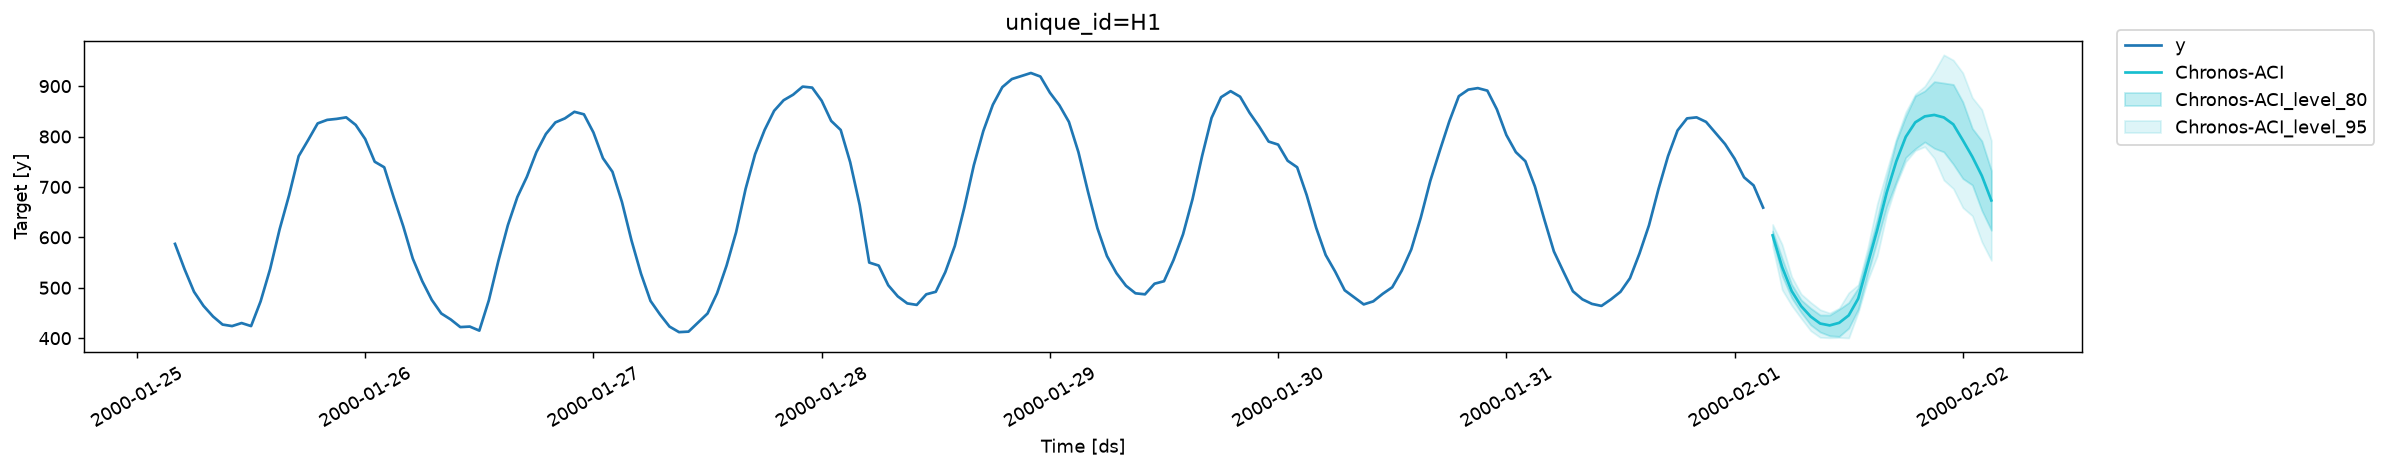

In [2]:
one_series = df[df["unique_id"] == df["unique_id"].iloc[0]].copy()
model = Chronos(
    repo_id="amazon/chronos-bolt-tiny",
    alias="Chronos-ACI",
    prediction_intervals=ConformalIntervals(
        n_windows=n_windows, method=ACI(gamma=0.005)
    ),
)
forecast = model.forecast(one_series, h=h, freq="h", level=level)
bounds = [c for c in forecast if "-lo-" in c or "-hi-" in c]
assert np.isfinite(forecast[bounds]).all().all()
forecast_fig = model.plot(
    one_series, forecast, level=level, max_insample_length=7 * h, plot_random=False
)
forecast_fig


## Held-out rolling-origin check

Evaluate four 24-hour origins on four M4 Hourly series (384 actuals per method and level). Each origin
calibrates exclusively on its training history. All variants share the same deterministic Chronos-Bolt tiny
point forecast, and all use 20 calibration windows. PID is symmetric for this comparison.

Coverage counts observations inside the returned interval. Mean width is in the original target units;
unbounded intervals have infinite width. The finite and empty fractions expose intervals that cannot be
used as ordinary finite bounds. Any ACI/PID warning about extreme bounds is retained in the output.


In [3]:
methods = {
    "Static-corrected": "conformal_error_finite_sample",
    "ACI": ACI(gamma=0.005),
    "PID": PID(symmetric=True),
}
models = [
    Chronos(
        repo_id="amazon/chronos-bolt-tiny",
        alias=alias,
        prediction_intervals=ConformalIntervals(
            n_windows=n_windows, method=method, step_size=h
        ),
    )
    for alias, method in methods.items()
]
ff = FoundationForecast(models=models)
cv = ff.cross_validation(df, h=h, freq="h", step_size=h, n_windows=4, level=level)
rows = []
for alias in methods:
    np.testing.assert_allclose(cv[alias], cv["Static-corrected"])
    for requested_level in level:
        lo, hi = cv[f"{alias}-lo-{requested_level}"], cv[f"{alias}-hi-{requested_level}"]
        empty = lo > hi
        width = (hi - lo).where(~empty, 0.0)
        rows.append(
            {
                "method": alias,
                "level": requested_level,
                "coverage": cv["y"].between(lo, hi).mean(),
                "mean_width": width.mean(),
                "finite_fraction": (np.isfinite(lo) & np.isfinite(hi)).mean(),
                "empty_fraction": empty.mean(),
            }
        )
coverage_summary = pd.DataFrame(rows)
coverage_summary.round(3)


method,level,coverage,mean_width,finite_fraction,empty_fraction
Static-corrected,80,0.917,304.239,1.0,0.0
Static-corrected,95,0.987,505.177,1.0,0.0
ACI,80,0.880,284.234,1.0,0.0
ACI,95,0.984,439.846,1.0,0.0
PID,80,0.875,331.595,1.0,0.0
PID,95,1.000,621.545,1.0,0.0


## Reading the results

The calibrators adjust intervals, not point predictions. Compare coverage and width together; wider or
unbounded sets can improve apparent coverage without giving useful uncertainty estimates. Empty sets
have zero width here and cover nothing; their fraction is reported separately. The methods may over-cover
or under-cover on this small dependent panel, and ACI can narrow intervals after repeated covers.

ACI adjusts alpha through `alpha += gamma * (target_alpha - miss)`. Errors are judged against the threshold
issued before their actual was known; a horizon-j score is only used j observations after its origin.
The score CDF uses exact empirical order statistics, without the separate finite-sample rank correction.
All state is local to a single replay. Output bounds are nested across levels; no claim of long-run,
per-cutoff or whole-horizon coverage follows from this example.

The existing [distribution-shift notebook](conformal-distribution-shift.ipynb) illustrates PID on changing
volatility. For the ACI update and its original online setting, see
[Gibbs and Candes (2021)](https://arxiv.org/abs/2106.00170).
